<Axes: xlabel='Height', ylabel='Weight'>

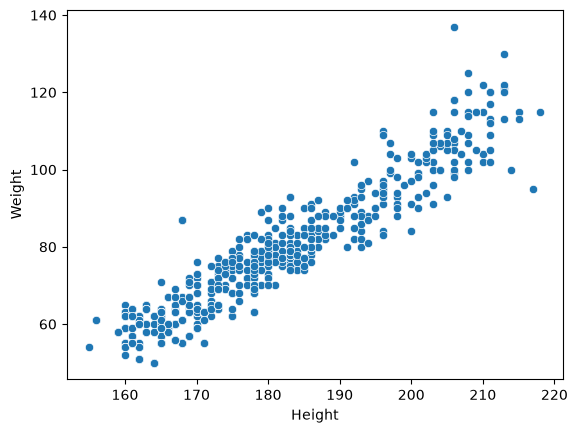

In [7]:
# workbook 3

import pandas as pd
import seaborn as sns
import duckdb
import matplotlib.pyplot as plt

olympics = pd.read_csv('olympics.csv')

# selects athletes from the olympics dataset, who participated in the 2016 summer games and are male, who play basketball, hockey, or gymnastics
athletes = duckdb.sql("""SELECT * 
                      FROM olympics 
                      WHERE Games = '2016 Summer' AND SEX = 'M'
                      AND (Sport = 'Basketball' OR Sport = 'Hockey' OR Sport = 'Gymnastics')""").df()

athletes.head()

# start by calling the basic scatterplot function
sns.scatterplot(athletes, x = "Height", y = "Weight")



<Axes: xlabel='Height', ylabel='Weight'>

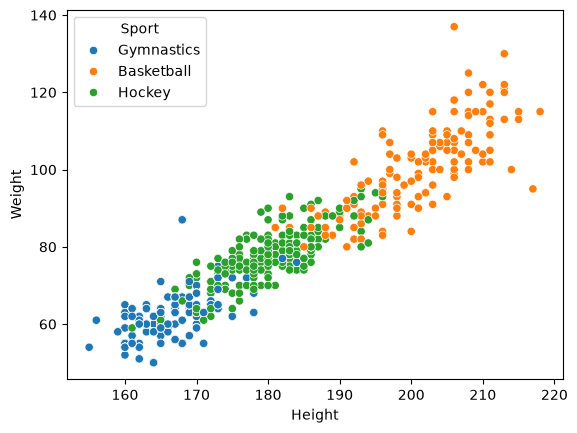

In [8]:

# the "hue" parameter automatically groups each subset by color, with a key
sns.scatterplot(athletes, x = "Height", y = "Weight", hue = "Sport")

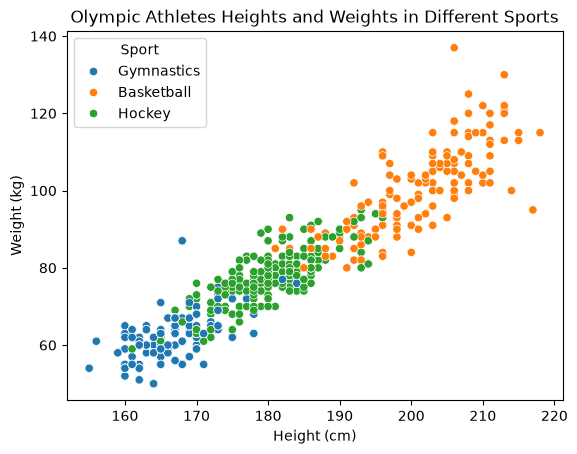

In [ ]:
sns.scatterplot(athletes, x = "Height", y = "Weight", hue = "Sport")

# this is matplotlib (plt) and does a lot more than seaborn

plt.xlabel('Height (cm)')
plt.ylabel('Weight (kg)')
plt.title('Olympic Athletes Heights and Weights in Different Sports')

# this actually shows the thing
plt.show()

In [11]:
# line plots

# manipulating the dataset to display dataset in line plot form

# use SQL
athletes_line = duckdb.sql("""SELECT Year, AVG(Height) AS AvgHeight
                                FROM olympics
                                WHERE Season = 'Summer' AND Sport = 'Basketball'
                                GROUP BY Year
                                ORDER BY Year ASC
                                """).df()
athletes_line.head()

,Year,AvgHeight
0,1936,182.574074
1,1948,185.550725
2,1952,187.600000
3,1956,186.952941
4,1960,188.317708


<Axes: xlabel='Year', ylabel='AvgHeight'>

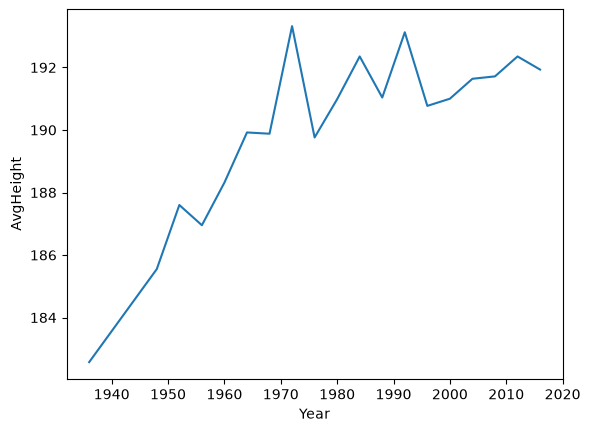

In [14]:
# graph using seaborn
sns.lineplot(athletes_line, x='Year', y='AvgHeight')

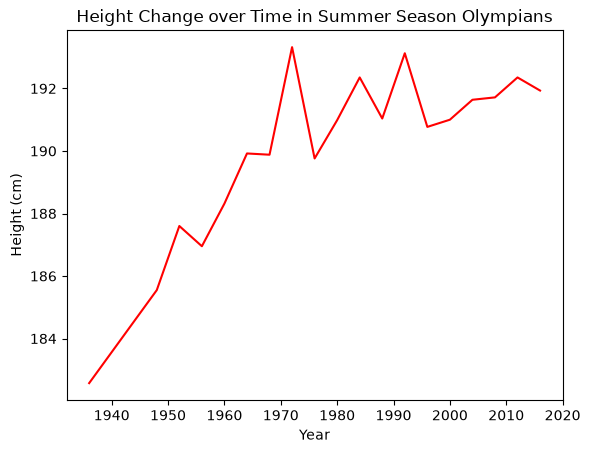

In [24]:
sns.lineplot(athletes_line, x = "Year", y = "AvgHeight", color = "red")

# can make this nicer using matplotlib

plt.xlabel('Year')
plt.ylabel('Height (cm)')
plt.title('Height Change over Time in Summer Season Olympians')

plt.show()

In [31]:
# bar plot

# first, filter the data
# note to self: figure out why it's COUNT(*) and how that works

medals_country = duckdb.sql("""SELECT Team, COUNT(*) as Golds
                                FROM olympics 
                                WHERE Medal = 'Gold' AND Year = 2012
                                GROUP BY Team
                                ORDER BY Golds DESC
                                LIMIT 10
                                """).df()

medals_country.head()

,Team,Golds
0,United States,139
1,Russia,50
2,China,50
3,Great Britain,46
4,Germany,43


<Axes: xlabel='Team', ylabel='Golds'>

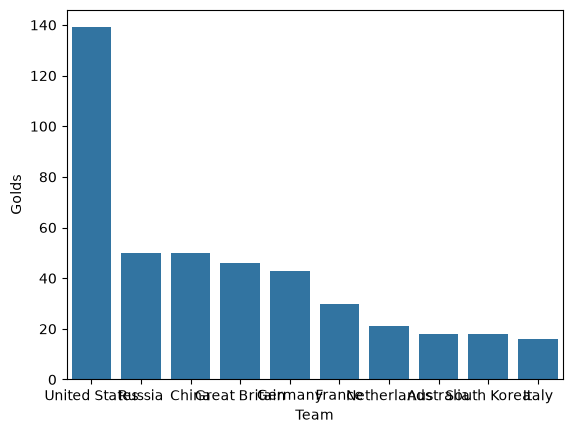

In [ ]:
# create the barplot

sns.barplot(medals_country, x = "Team", y = "Golds")

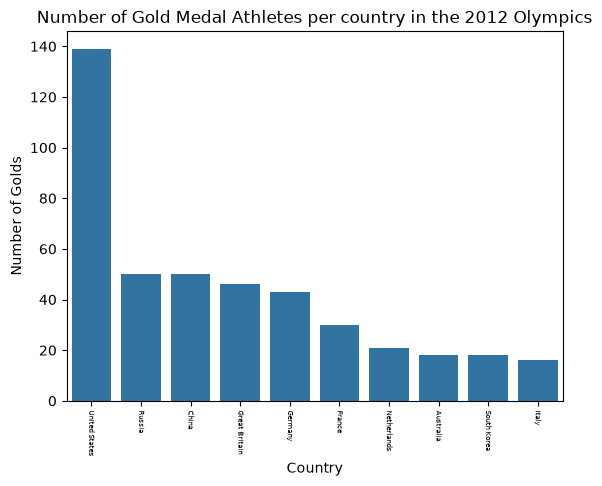

In [33]:
# improve the barplot

sns.barplot(medals_country, x = "Team", y = "Golds")

# display country names horizontally and set font size
plt.xticks(rotation = -90, fontsize = 5)

plt.xlabel('Country')
plt.ylabel('Number of Golds')
plt.title('Number of Gold Medal Athletes per country in the 2012 Olympics')
plt.show()

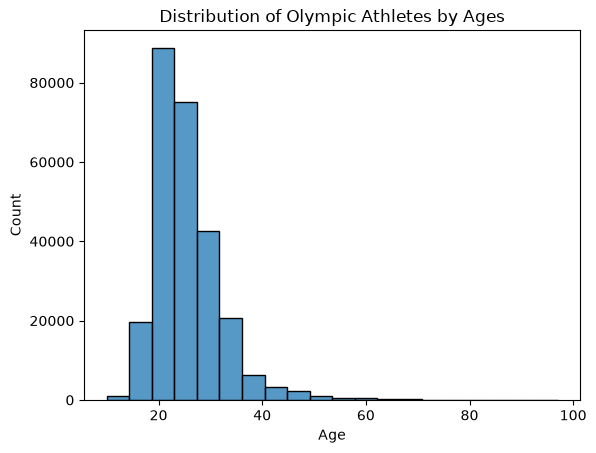

In [ ]:
# histogram function (histplot)

sns.histplot(olympics, x='Age', bins = 20)
# the bins = 20 bit specifies how far apart each line on the x-axis will be

plt.title('Distribution of Olympic Athletes by Ages')
plt.show()

In [37]:
# filter the dataset to just the 100 meter dash from the 2016 summer olympics
# make a scatterplot of each of the athletes height vs weight
# change the hue parameter to change color based on the medal category

dash_score = duckdb.sql("""SELECT * 
                                FROM olympics 
                                WHERE Event LIKE '%100 metres%' AND Games = '2016 Summer' AND Sex = 'M' AND Sport = 'Athletics'
                                """).df()

dash_score['Medal'] = dash_score['Medal'].fillna("")


In [39]:
dash_score.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,611,Mohammed Abukhousa,M,23.0,170.0,67.0,Palestine,PLE,2016 Summer,2016,Summer,Rio de Janeiro,Athletics,Athletics Men's 100 metres,
1,804,Antoine Xavier Adams,M,27.0,180.0,79.0,Saint Kitts and Nevis,SKN,2016 Summer,2016,Summer,Rio de Janeiro,Athletics,Athletics Men's 100 metres,
2,804,Antoine Xavier Adams,M,27.0,180.0,79.0,Saint Kitts and Nevis,SKN,2016 Summer,2016,Summer,Rio de Janeiro,Athletics,Athletics Men's 4 x 100 metres Relay,
3,1421,Masbah Ahmmed,M,21.0,NaN,NaN,Bangladesh,BAN,2016 Summer,2016,Summer,Rio de Janeiro,Athletics,Athletics Men's 100 metres,
4,1488,Harry Leslie Aikines-Aryeetey,M,27.0,180.0,87.0,Great Britain,GBR,2016 Summer,2016,Summer,Rio de Janeiro,Athletics,Athletics Men's 4 x 100 metres Relay,


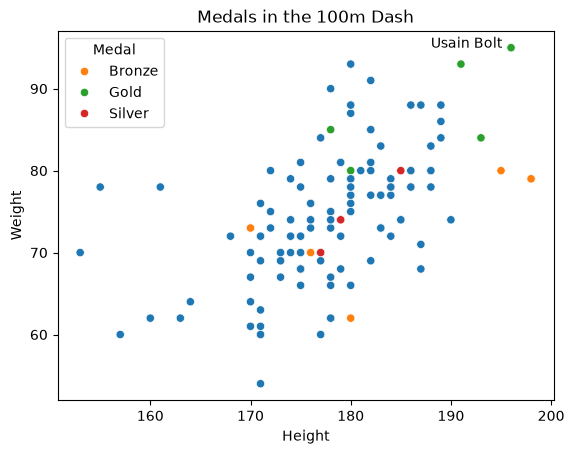

In [43]:
# create scatterplot
# the hue can also be specified-- you can base it on a certain parameter
sns.scatterplot(dash_score, x='Height', y='Weight', hue = 'Medal')

# puts an annotation at the desired xy coordinate
plt.annotate(text = 'Usain Bolt', xy = (188, 95))

plt.title('Medals in the 100m Dash')
plt.xlabel('Height')
plt.ylabel('Weight')
plt.show()

In [ ]:
# %pip install plotly
# has its own syntax but is useful for dynamic and interactive visualizations

import plotly.express as px


In [ ]:
# make a subset of the original olympics dataset and filter for 1992 summer games, male athletes, USA team, basketball

dream_team = duckdb.sql(""" SELECT * FROM olympics
                        WHERE Games = '1992 Summer' AND Sex = 'M' AND Team = 'United States' AND Sport = 'Basketball'
                    """).df()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,7901,Charles Wade Barkley,M,29.0,198.0,114.0,United States,USA,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,Gold
1,11668,Larry Joe Bird,M,35.0,205.0,100.0,United States,USA,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,Gold
2,30009,Clyde Austin Drexler,M,30.0,200.0,101.0,United States,USA,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,Gold
3,33553,Patrick Aloysius Ewing,M,29.0,213.0,109.0,United States,USA,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,Gold
4,55424,"Earvin ""Magic"" Johnson, Jr.",M,32.0,205.0,100.0,United States,USA,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,Gold
5,55881,Michael Jeffrey Jordan,M,29.0,198.0,90.0,United States,USA,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,Gold
6,65809,Christian Donald Laettner,M,22.0,211.0,107.0,United States,USA,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,Gold
7,74176,Karl Malone,M,29.0,205.0,116.0,United States,USA,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,Gold
8,83179,"Christopher Paul ""Chris"" Mullin",M,28.0,200.0,98.0,United States,USA,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,Gold
9,95105,Scottie Maurice Pippen,M,26.0,200.0,102.0,United States,USA,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,Gold


In [ ]:
# make the plotly plot

fig = px.scatter(dream_team, x='Height', y='Weight', text='Name', width=800, height=500)
fig.update_layout(title = '1992 Dream Team players heights and weights', xaxis_title = 'Height in cm', yaxis_title = 'Weight in kg')
fig.show()

# the below chart is interactive, you can zoom in and whatnot
